# model-3: EfficientNetV2B0

Notebook pasangan **model-3** (**Tegar**: trial 1-5 | **Sony**: trial 6-10). Simpan sebagai `model-3/model-3_efficientnetv2b0.ipynb`.
Versi 2 (8 November 2026): data dibaca dari dataset Kaggle `simplicity-224-letterbox`.

**Ide kunci arsitektur:** *Compound scaling* (penyetaraan kedalaman, lebar, dan resolusi jaringan secara terukur) yang dipadukan dengan blok **Fused-MBConv** pada tahap awal untuk mengekstrak fitur spasial secara efisien dan **MBConv + Squeeze-and-Excitation (SE)** pada tahap akhir.

**Pengaturan Kaggle (wajib):**
- *Settings > Accelerator*: GPU (T4 atau P100)
- *Settings > Internet*: **ON**, untuk `git clone` dan unduh bobot ImageNet (butuh verifikasi nomor HP)
- *Add Input* (panel kanan): cari dataset `simplicity-224-letterbox` milik `yonobengkel12`, lalu tambahkan. Isinya gambar 224×224 yang sudah jadi dan identik dengan hasil `data_utils.py`, jadi semua pasangan memakai input yang persis sama.
- Untuk pelatihan panjang, pakai *Save Version > Save & Run All* agar tetap berjalan walau browser ditutup.

**Aturan:** sel bertanda `JANGAN DIUBAH` dipakai apa adanya. `common/data_utils.py` dikunci dan hanya dipakai lewat import.

## 1. Setup bersama (JANGAN DIUBAH)
Clone repo (di Kaggle) atau cari root repo (di lokal), import `data_utils`, cetak sidik versinya, lalu cek perangkat.
Sidik yang tercetak harus sama dengan sidik resmi di README bagian 3 (per 8 November 2026: `b3e0629783c5`).

In [1]:
# ===== SETUP BERSAMA: JANGAN DIUBAH =====
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/0Raja0-RA/simplicity-cnn-comparison.git"
BRANCH = "main"

if Path("/kaggle/working").exists():                      # di Kaggle
    ROOT = Path("/kaggle/working/simplicity-cnn-comparison")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(ROOT)], check=True)
else:                                                     # di lokal: naik sampai ketemu root repo
    ROOT = Path.cwd().resolve()
    while not (ROOT / "common" / "data_utils.py").exists():
        if ROOT.parent == ROOT:
            raise FileNotFoundError("Root repo (berisi common/data_utils.py) tidak ditemukan.")
        ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
from common import data_utils as du

SIDIK = du.sidik_config()
INFO_PERANGKAT = du.cek_perangkat()
print("ROOT:", ROOT)

Sidik data_utils.py: b3e0629783c5  (lengkap: b3e0629783c56e87dc773010969802b88aaa44e43bc811bba5a553ff7a9aee6e)
GPU: Tesla T4
GPU: Tesla T4
TensorFlow 2.21.0
Memakai GPU
Kalau terjadi out-of-memory (OOM), turunkan batch size.
ROOT: /kaggle/working/simplicity-cnn-comparison


## 2. Data (JANGAN DIUBAH, kecuali `BATCH_SIZE`)
Gambar float32 0-255 berukuran `du.IMG_SIZE`, sudah di-padding, belum dinormalisasi. Label integer 0-9
(pakai `sparse_categorical_crossentropy`). Augmentasi **tidak** ada di dataset; pasang `du.get_augmentation()` di model.
`du.load_data()` mencetak sumber data. Di Kaggle harus tertulis `simplicity_224.npz (npz dataset Kaggle)`; sel ini berhenti dengan pesan galat kalau dataset belum dipasang.

In [2]:
BATCH_SIZE = 32          # boleh diubah per pasangan (README bagian 5)

# Di Kaggle, dataset simplicity-224-letterbox wajib terpasang (Add Input) supaya semua pasangan memakai gambar yang sama persis
if Path("/kaggle/working").exists() and not any(Path("/kaggle/input").rglob(du.NPZ_NAMA)):
    raise RuntimeError(f"Dataset Kaggle {du.KAGGLE_DATASET} belum dipasang. "
                       "Tambahkan lewat Add Input di panel kanan, lalu jalankan ulang sel ini.")

train_ds, val_ds = du.load_data(batch_size=BATCH_SIZE)   # mencetak sumber data: harus simplicity_224.npz
CLASS_NAMES = du.get_class_names()
print("IMG_SIZE:", du.IMG_SIZE, "| kelas:", CLASS_NAMES)

PERINGATAN: manifest belum dibuat (manifest.csv); pemeriksaan hash dilewati.
Sumber data: /kaggle/input/datasets/yonobengkel12/simplicity-224-letterbox/simplicity_224.npz (npz dataset Kaggle)
IMG_SIZE: (224, 224) | kelas: ['People', 'Beach', 'Building', 'Bus', 'Dinosaur', 'Elephant', 'Flower', 'Horse', 'Mountain', 'Food']


## 3. Model: EfficientNetV2B0
Urutan di dalam model mengikuti ketentuan wajib:
`Input(du.IMG_SIZE + (3,))` -> `du.get_augmentation()` -> `efficientnet_v2.preprocess_input` -> `EfficientNetV2B0(include_top=False, weights="imagenet", include_preprocessing=True)` -> head klasifikasi 10 kelas (`softmax`).

**Catatan normalisasi & fine-tuning:**
- `EfficientNetV2B0` di Keras (`include_preprocessing=True`) sudah menyertakan layer normalisasi internal yang menerima piksel float32 rentang `[0, 255]`. Fungsi `keras.applications.efficientnet_v2.preprocess_input` bersifat *pass-through* (mengembalikan tensor apa adanya), sehingga urutan wajib tetap dipatuhi tanpa terjadi normalisasi ganda.
- Saat *fine-tuning* (`unfreeze_pct > 0`), hanya persentase layer teratas backbone yang dibuka, sedangkan seluruh layer `BatchNormalization` tetap dibekukan (`trainable = False`) agar statistik rata-rata dan varians ImageNet tidak rusak pada dataset kecil (500 gambar latih).

In [3]:
from tensorflow import keras


def bangun_model(
    learning_rate: float = 3e-4,
    unfreeze_pct: float = 0.0,
    optimizer: str = "adamw",
    weight_decay: float = 1e-4,
    dropout: float = 0.3,
    head_units: int = 0,
):
    """Bangun dan compile model EfficientNetV2B0 untuk 10 kelas SIMPLIcity."""
    inputs = keras.Input(shape=du.IMG_SIZE + (3,), name="input_gambar")

    # 1. Augmentasi wajib dari data_utils (aktif hanya saat training=True)
    x = du.get_augmentation()(inputs)

    # 2. Normalisasi: EfficientNetV2B0 (include_preprocessing=True) sudah menormalisasi
    # piksel [0, 255] di dalam backbone-nya. preprocess_input milik efficientnet_v2
    # adalah pass-through (mengembalikan x tanpa perubahan), jadi aman dari normalisasi ganda.
    x = keras.applications.efficientnet_v2.preprocess_input(x)

    # 3. Backbone pretrained ImageNet
    base = keras.applications.EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        pooling="avg",
        include_preprocessing=True,
    )

    if unfreeze_pct <= 0.0:
        base.trainable = False
        x = base(x, training=False)
    else:
        base.trainable = True
        batas_beku = int(len(base.layers) * (1.0 - unfreeze_pct))
        for idx, layer in enumerate(base.layers):
            # Bekukan layer bawah serta semua BatchNormalization agar statistik ImageNet stabil
            if idx < batas_beku or isinstance(layer, keras.layers.BatchNormalization):
                layer.trainable = False
            else:
                layer.trainable = True
        x = base(x)

    # 4. Head klasifikasi 10 kelas
    x = keras.layers.Dropout(dropout, seed=du.SEED, name="head_dropout")(x)
    if head_units > 0:
        x = keras.layers.Dense(head_units, activation="swish", name="head_dense")(x)
        x = keras.layers.Dropout(dropout * 0.5, seed=du.SEED, name="head_dropout_2")(x)
    outputs = keras.layers.Dense(len(CLASS_NAMES), activation="softmax", name="prediksi")(x)

    model = keras.Model(inputs, outputs, name="model3_efficientnetv2b0")

    wd_float = float(weight_decay)
    wd_optional = wd_float if wd_float > 0.0 else None
    nama_opt = optimizer.lower()
    if nama_opt == "adamw":
        opt = keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=wd_float)
    elif nama_opt == "rmsprop":
        opt = keras.optimizers.RMSprop(learning_rate=learning_rate, weight_decay=wd_optional)
    elif nama_opt == "adam":
        opt = keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=wd_optional)
    else:
        raise ValueError(f"Optimizer tidak dikenal: {optimizer}")

    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


# Uji ringkas struktur model (lalu bersihkan sesi sebelum tuning)
du.set_seed(du.SEED)
_cek_model = bangun_model()
_cek_model.summary()
del _cek_model
keras.backend.clear_session()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "model3_efficientnetv2b0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_gambar (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 1280)           │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediksi (Dense)                │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,932,122 (22.63 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

## 4. Tuning: random search (10 trial, dibagi Tegar 1-5 & Sony 6-10)
- **Pengaturan seragam kelompok:** 10 trial unik dibangkitkan di awal dengan `du.SEED` (`42`), maksimum `40` epoch, dan `EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)`.
- **Pembagian eksekusi:** ubah `PELAKSANA = "tegar"` (trial 1-5 -> `trials_tegar.csv`) atau `PELAKSANA = "sony"` (trial 6-10 -> `trials_sony.csv`). Karena kesepuluh kombinasi dibangkitkan lebih dulu dengan seed `42`, daftar kombinasi di akun Tegar dan akun Sony dijamin identik.
- **Alasan pemilihan ruang pencarian `EfficientNetV2B0`:**
  - `learning_rate` (`1e-4`, `3e-4`, `5e-4`, `1e-3`): rentang efektif untuk transfer learning dalam batas 40 epoch (~16-32 langkah per epoch pada 500 gambar).
  - `unfreeze_pct` (`0.0`, `0.2`, `0.35`): menjaga blok awal **Fused-MBConv** tetap beku (fitur tepi/tekstur umum) dan menguji pembukaan blok **MBConv + SE** teratas (0%, 20%, 35%).
  - `optimizer` (`adamw`, `rmsprop`): membandingkan `RMSprop` (optimizer asli paper EfficientNetV2) dengan `AdamW` modern.
  - `weight_decay` (`0.0`, `1e-4`, `1e-3`) & `dropout` (`0.2`, `0.3`, `0.5`): menguji kekuatan regularisasi terhadap risiko overfitting pada 50 gambar latih per kelas.
  - `head_units` (`0`, `128`, `256`): membandingkan proyeksi linear langsung (`0`) dengan tambahan hidden layer beraktivasi `swish` khas EfficientNetV2.
  - `batch_size` (`16`, `32`): menguji trade-off regularisasi implisit dari variasi gradien batch kecil (`16`) dibanding kestabilan batch standar (`32`).


In [4]:
import csv
import json
import random
import tempfile
import time
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# PILIH PELAKSANA DI AKUN KAGGLE MASING-MASING:
#   "tegar" -> menjalankan trial 1-5  (dicatat ke model-3/trials_tegar.csv)
#   "sony"  -> menjalankan trial 6-10 (dicatat ke model-3/trials_sony.csv)
#   "semua" -> menjalankan trial 1-10 (dicatat ke model-3/trials.csv)
# =====================================================================
PELAKSANA = "semua"    # owner: sony (trial 6-10)

N_TRIALS = 10
MAX_EPOCHS = 40
PATIENCE = 8

JATAH_PER_ORANG = {
    "tegar": range(1, 6),
    "sony": range(6, 11),
    "semua": range(1, 11),
}
if PELAKSANA not in JATAH_PER_ORANG:
    raise ValueError(f"PELAKSANA harus salah satu dari {list(JATAH_PER_ORANG)}, bukan {PELAKSANA!r}")

JATAH_TRIAL = list(JATAH_PER_ORANG[PELAKSANA])

# Folder repo model-3: mendahulukan model-3_EfficientNetV2B0 / model-3_efficientnetv2b0 (nama lama model-3 tetap didukung)
if (ROOT / "model-3_EfficientNetV2B0").is_dir():
    MODEL_DIR = ROOT / "model-3_EfficientNetV2B0"
elif (ROOT / "model-3_efficientnetv2b0").is_dir():
    MODEL_DIR = ROOT / "model-3_efficientnetv2b0"
elif (ROOT / "model-3").is_dir():
    MODEL_DIR = ROOT / "model-3"
else:
    MODEL_DIR = ROOT / "model-3_EfficientNetV2B0"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if Path("/kaggle/working").exists():
    CKPT_DIR = Path("/kaggle/working/output_model3")
else:
    CKPT_DIR = Path(tempfile.gettempdir()) / "output_model3"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
assert ROOT.resolve() not in CKPT_DIR.resolve().parents and CKPT_DIR.resolve() != ROOT.resolve(), (
    "Berkas .keras dilarang disimpan di dalam folder repo!"
)

# [TAMBAHAN] Folder gambar di DALAM repo (learning curve trial terbaik) agar bisa di-push ke GitHub
GAMBAR_DIR = MODEL_DIR / f"gambar_{PELAKSANA}"
GAMBAR_DIR.mkdir(parents=True, exist_ok=True)

CSV_AKTIF = MODEL_DIR / ("trials.csv" if PELAKSANA == "semua" else f"trials_{PELAKSANA}.csv")
CSV_GABUNGAN = MODEL_DIR / "trials.csv"

# Ruang pencarian khusus EfficientNetV2B0
URUTAN_PARAM = (
    "learning_rate",
    "unfreeze_pct",
    "optimizer",
    "weight_decay",
    "dropout",
    "head_units",
    "batch_size",
)
RUANG_CARI = {
    "learning_rate": [1e-4, 3e-4, 5e-4, 1e-3],
    "unfreeze_pct": [0.0, 0.2, 0.35],
    "optimizer": ["adamw", "rmsprop"],
    "weight_decay": [0.0, 1e-4, 1e-3],
    "dropout": [0.2, 0.3, 0.5],
    "head_units": [0, 128, 256],
    "batch_size": [16, 32],
}

KOLOM_CSV = ["trial", *URUTAN_PARAM, "val_acc", "val_loss", "best_epoch", "train_time_sec"]

# Bangkitkan 10 kombinasi unik di awal dengan du.SEED (42) agar sama persis di semua akun
rng = random.Random(du.SEED)
DAFTAR_TRIAL = []
_kombinasi_terpakai = set()
while len(DAFTAR_TRIAL) < N_TRIALS:
    kandidat = {k: rng.choice(RUANG_CARI[k]) for k in URUTAN_PARAM}
    kunci = tuple(kandidat[k] for k in URUTAN_PARAM)
    if kunci not in _kombinasi_terpakai:
        _kombinasi_terpakai.add(kunci)
        DAFTAR_TRIAL.append({"trial": len(DAFTAR_TRIAL) + 1, **kandidat})

print("Daftar 10 kombinasi parameter (seed = 42, identik untuk Tegar & Sony):")
for cfg in DAFTAR_TRIAL:
    tanda = " <-- jatah aktif" if cfg["trial"] in JATAH_TRIAL else ""
    print(
        f"  Trial {cfg['trial']:>2}: lr={cfg['learning_rate']}, unfreeze={cfg['unfreeze_pct']}, "
        f"opt={cfg['optimizer']:<7}, wd={cfg['weight_decay']}, drop={cfg['dropout']}, "
        f"head={cfg['head_units']:>3}, bs={cfg['batch_size']}{tanda}"
    )


def baca_csv_trial(path: Path) -> list[dict]:
    if not path.is_file():
        return []
    with open(path, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def skor_trial(row: dict) -> tuple[float, float]:
    """Urutan pemilihan: val_acc tertinggi, kalau seri pilih val_loss terendah."""
    return (float(row["val_acc"]), -float(row["val_loss"]))


def simpan_grafik_history(history_dict: dict, info_trial: dict, path_png: Path):
    epochs = range(1, len(history_dict["loss"]) + 1)
    best_ep = int(info_trial["best_epoch"])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(epochs, history_dict["loss"], label="Train Loss", linewidth=2)
    axes[0].plot(epochs, history_dict["val_loss"], label="Val Loss", linewidth=2)
    axes[0].axvline(best_ep, color="grey", linestyle="--", label=f"Best Epoch ({best_ep})")
    axes[0].set_title("Kurva Loss (Gradient Descent)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Sparse Categorical Crossentropy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history_dict["accuracy"], label="Train Accuracy", linewidth=2)
    axes[1].plot(epochs, history_dict["val_accuracy"], label="Val Accuracy", linewidth=2)
    axes[1].axvline(best_ep, color="grey", linestyle="--", label=f"Best Epoch ({best_ep})")
    axes[1].set_title("Kurva Akurasi")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(
        f"EfficientNetV2B0 - Trial #{info_trial['trial']} "
        f"(val_acc={float(info_trial['val_acc']):.4f}, val_loss={float(info_trial['val_loss']):.4f})",
        fontsize=12,
        fontweight="bold",
    )
    fig.tight_layout()
    fig.savefig(path_png, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Cek trial yang sudah selesai (agar aman melanjutkan kalau sesi Kaggle terputus)
baris_selesai = baca_csv_trial(CSV_AKTIF)
id_selesai = {int(r["trial"]) for r in baris_selesai}
if CSV_GABUNGAN.is_file():
    id_selesai |= {int(r["trial"]) for r in baca_csv_trial(CSV_GABUNGAN)}

terbaik_sesi = max(baris_selesai, key=skor_trial) if baris_selesai else None

print(f"\nPelaksana aktif : {PELAKSANA} (jatah trial: {JATAH_TRIAL})")
print(f"Berkas log CSV  : {CSV_AKTIF}")
print(f"Folder .keras   : {CKPT_DIR} (di luar repo)")

for cfg in DAFTAR_TRIAL:
    no_trial = cfg["trial"]
    if no_trial not in JATAH_TRIAL:
        continue
    if no_trial in id_selesai:
        print(f"[SKIP] Trial {no_trial} sudah tercatat sebelumnya.")
        continue

    print(f"\n{'=' * 70}")
    print(f"Menjalankan Trial {no_trial}/{N_TRIALS} | Konfigurasi: {cfg}")
    print(f"{'=' * 70}")

    keras.backend.clear_session()
    train_ds_t, val_ds_t = du.load_data(batch_size=cfg["batch_size"])

    model = bangun_model(
        learning_rate=cfg["learning_rate"],
        unfreeze_pct=cfg["unfreeze_pct"],
        optimizer=cfg["optimizer"],
        weight_decay=cfg["weight_decay"],
        dropout=cfg["dropout"],
        head_units=cfg["head_units"],
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1,
    )

    t_mulai = time.perf_counter()
    hist = model.fit(
        train_ds_t,
        validation_data=val_ds_t,
        epochs=MAX_EPOCHS,
        callbacks=[early_stop],
        verbose=1,
    )
    durasi = round(time.perf_counter() - t_mulai, 2)

    best_epoch = int(np.argmin(hist.history["val_loss"]) + 1)
    val_loss, val_acc = model.evaluate(val_ds_t, verbose=0)

    baris_baru = {
        "trial": no_trial,
        **{k: cfg[k] for k in URUTAN_PARAM},
        "val_acc": f"{val_acc:.6f}",
        "val_loss": f"{val_loss:.6f}",
        "best_epoch": best_epoch,
        "train_time_sec": f"{durasi:.2f}",
    }

    tulis_header = not CSV_AKTIF.is_file()
    with open(CSV_AKTIF, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=KOLOM_CSV, lineterminator="\n")
        if tulis_header:
            writer.writeheader()
        writer.writerow(baris_baru)

    baris_selesai.append(baris_baru)
    print(
        f"-> Selesai Trial {no_trial}: val_acc={val_acc:.4f} | val_loss={val_loss:.4f} "
        f"| best_epoch={best_epoch} | waktu={durasi:.2f}s"
    )

    # Jika trial ini menjadi yang terbaik sejauh ini, simpan .keras (di luar repo) dan perbarui grafik
    if terbaik_sesi is None or skor_trial(baris_baru) > skor_trial(terbaik_sesi):
        for lama in CKPT_DIR.glob(f"best_{PELAKSANA}_trial*.keras"):
            lama.unlink()
        path_keras = CKPT_DIR / f"best_{PELAKSANA}_trial{no_trial}_efficientnetv2b0.keras"
        model.save(path_keras)

        with open(CKPT_DIR / f"best_history_{PELAKSANA}.json", "w", encoding="utf-8") as fh:
            json.dump({k: [float(v) for v in vals] for k, vals in hist.history.items()}, fh)

        # [TAMBAHAN] Learning curve trial terbaik untuk di-push ke GitHub (disimpan ke folder pelaksana agar tidak bentrok)
        path_kurva_terbaik = GAMBAR_DIR / "learning_curve_terbaik.png" if PELAKSANA != "semua" else MODEL_DIR / "history_efficientnetv2b0.png"
        simpan_grafik_history(hist.history, baris_baru, path_kurva_terbaik)
        print(f"   Learning curve terbaik disimpan ke {path_kurva_terbaik}")
        terbaik_sesi = baris_baru
        print(f"   [TERBAIK BARU] Model disimpan ke {path_keras}")


# Otomatis gabungkan trials_tegar.csv + trials_sony.csv -> model-3/trials.csv bila keduanya sudah ada
csv_tegar = MODEL_DIR / "trials_tegar.csv"
csv_sony = MODEL_DIR / "trials_sony.csv"
if csv_tegar.is_file() and csv_sony.is_file():
    gabung = {int(r["trial"]): r for r in baca_csv_trial(csv_tegar) + baca_csv_trial(csv_sony)}
    urut = [gabung[k] for k in sorted(gabung)]
    with open(CSV_GABUNGAN, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=KOLOM_CSV, lineterminator="\n")
        writer.writeheader()
        writer.writerows(urut)
    print(f"\n[INFO] Berhasil menggabungkan {len(urut)} trial ke {CSV_GABUNGAN}")

# Ringkasan hasil terbaik yang tersedia saat ini
sumber_ringkasan = CSV_GABUNGAN if CSV_GABUNGAN.is_file() else CSV_AKTIF
semua_baris = baca_csv_trial(sumber_ringkasan)
if semua_baris:
    pemenang = max(semua_baris, key=skor_trial)
    print(f"\n=== RINGKASAN TERBAIK DARI {sumber_ringkasan.name} ({len(semua_baris)} trial) ===")
    for k, v in pemenang.items():
        print(f"  {k:<16}: {v}")

Daftar 10 kombinasi parameter (seed = 42, identik untuk Tegar & Sony):
  Trial  1: lr=0.0001, unfreeze=0.0, opt=rmsprop, wd=0.0, drop=0.2, head=  0, bs=16 <-- jatah aktif
  Trial  2: lr=0.0001, unfreeze=0.35, opt=rmsprop, wd=0.0, drop=0.2, head=  0, bs=16 <-- jatah aktif
  Trial  3: lr=0.0003, unfreeze=0.35, opt=adamw  , wd=0.001, drop=0.2, head=256, bs=32 <-- jatah aktif
  Trial  4: lr=0.0003, unfreeze=0.2, opt=rmsprop, wd=0.0, drop=0.2, head=256, bs=32 <-- jatah aktif
  Trial  5: lr=0.0005, unfreeze=0.2, opt=adamw  , wd=0.0, drop=0.3, head=  0, bs=16 <-- jatah aktif
  Trial  6: lr=0.001, unfreeze=0.0, opt=rmsprop, wd=0.0001, drop=0.5, head=128, bs=16 <-- jatah aktif
  Trial  7: lr=0.001, unfreeze=0.35, opt=adamw  , wd=0.0001, drop=0.2, head=256, bs=32 <-- jatah aktif
  Trial  8: lr=0.0005, unfreeze=0.35, opt=adamw  , wd=0.001, drop=0.2, head=  0, bs=16 <-- jatah aktif
  Trial  9: lr=0.0005, unfreeze=0.0, opt=adamw  , wd=0.0, drop=0.3, head=128, bs=32 <-- jatah aktif
  Trial 10: lr=0.

## 4a. Sambungkan akun GitHub (TAMBAHAN, owner: sony / `Sony1866`)
Menghubungkan GitHub lewat menu Kaggle (*File > Link to GitHub / Upload to GitHub*) hanya mengunggah berkas `.ipynb` dari antarmuka Kaggle.
Kode di dalam notebook **tidak** mendapat izin git dari situ, jadi untuk push otomatis perlu token:

1. Di GitHub (akun `Sony1866`): *Settings > Developer settings > Personal access tokens*, buat token dengan akses tulis (*Contents: Read and write*) ke repo `0Raja0-RA/simplicity-cnn-comparison`.
2. Pastikan `Sony1866` sudah diundang sebagai **collaborator** di repo tersebut oleh pemilik repo.
3. Di Kaggle: *Add-ons > Secrets*, tambahkan secret `GITHUB_TOKEN` berisi token tadi, lalu centang secret itu untuk notebook ini.

Kalau sel ini mencetak `TERSAMBUNG`, sel 4b akan push otomatis.


In [5]:
# ===== TAMBAHAN: SAMBUNGKAN AKUN GITHUB (owner: sony) =====
import urllib.error
import urllib.request

GITHUB_USER = "Sony1866"
GITHUB_TOKEN = ""  # Diisi otomatis via Kaggle Secrets atau os.environ
GITHUB_TERHUBUNG = False

# 1. Ambil token dari Kaggle Secrets (atau variabel lingkungan kalau di lokal)
try:
    if Path("/kaggle/working").exists():
        from kaggle_secrets import UserSecretsClient
        GITHUB_TOKEN = UserSecretsClient().get_secret("GITHUB_TOKEN")
    else:
        import os
        GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN")
    if GITHUB_TOKEN:
        GITHUB_TOKEN = GITHUB_TOKEN.strip()
except Exception as e:
    print("Secret GITHUB_TOKEN belum dipasang / belum dicentang untuk notebook ini:", e)


def _github_api(url: str) -> dict:
    req = urllib.request.Request(url, headers={
        "Authorization": f"Bearer {GITHUB_TOKEN}",
        "Accept": "application/vnd.github+json",
        "User-Agent": "kaggle-notebook-model-3",
    })
    with urllib.request.urlopen(req, timeout=20) as r:
        return json.load(r)


# 2. Cek token valid, akun benar, dan punya izin push ke repo
if GITHUB_TOKEN:
    try:
        akun = _github_api("https://api.github.com/user")
        print("Login GitHub sebagai :", akun["login"])
        if akun["login"].lower() != GITHUB_USER.lower():
            print(f"PERINGATAN: token milik {akun['login']}, bukan {GITHUB_USER}.")

        owner_repo = REPO_URL.removeprefix("https://github.com/").removesuffix(".git")
        repo = _github_api(f"https://api.github.com/repos/{owner_repo}")
        bisa_push = repo.get("permissions", {}).get("push", False)
        print(f"Repo                 : {owner_repo} | izin push: {bisa_push}")

        if bisa_push:
            # Uji koneksi git ke repo (tanpa mengubah apa pun)
            url_cek = REPO_URL.replace("https://", f"https://x-access-token:{GITHUB_TOKEN}@")
            cek = subprocess.run(["git", "ls-remote", "--heads", url_cek, BRANCH],
                                 capture_output=True, text=True)
            GITHUB_TERHUBUNG = cek.returncode == 0
            if not GITHUB_TERHUBUNG:
                print("git ls-remote gagal:", cek.stderr.replace(GITHUB_TOKEN, "***"))
        else:
            print(f"Akun {akun['login']} belum punya izin tulis. Minta pemilik repo menambahkan sebagai collaborator.")
    except urllib.error.HTTPError as e:
        print(f"Gagal cek GitHub (HTTP {e.code}): token salah/kedaluwarsa atau repo tidak bisa diakses.")
    except Exception as e:
        print(f"Gagal cek GitHub: {e}")
else:
    print("Token GitHub tidak ditemukan.")

print("\nStatus GitHub:", "TERSAMBUNG (push otomatis aktif)" if GITHUB_TERHUBUNG else "BELUM TERSAMBUNG")

Secret GITHUB_TOKEN belum dipasang / belum dicentang untuk notebook ini: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 143437590 and label GITHUB_TOKEN.'], 'error': {'code': 5}, 'wasSuccessful': False}.
Login GitHub sebagai : Sony1866
Repo                 : 0Raja0-RA/simplicity-cnn-comparison | izin push: True

Status GitHub: TERSAMBUNG (push otomatis aktif)


## 4b. Simpan hasil ke GitHub (TAMBAHAN, owner: sony)
Commit & push `trials_<pelaksana>.csv` dan folder `model-3/gambar_<pelaksana>/` (learning curve trial terbaik) ke repo.
Berkas `.keras` tetap di luar repo dan **tidak** ikut di-push.

Syarat di Kaggle: *Add-ons > Secrets*, tambahkan secret bernama `GITHUB_TOKEN` (Personal Access Token GitHub dengan akses tulis ke repo), lalu ubah `PUSH_KE_GITHUB = True`.


In [6]:
# ===== TAMBAHAN: SIMPAN KE GITHUB (owner: sony) =====
PUSH_KE_GITHUB = GITHUB_TERHUBUNG # otomatis True kalau sel "Sambungkan akun GitHub" berhasil
GIT_NAMA = "sony"
GIT_EMAIL = "egyantabarekasby@gmail.com"


def git(*args, cek=True):
    res = subprocess.run(["git", "-C", str(ROOT), *args], capture_output=True, text=True)
    if cek and res.returncode != 0:
        pesan = res.stderr or res.stdout
        if GITHUB_TOKEN:
            pesan = pesan.replace(GITHUB_TOKEN, "***")
        cmd_str = " ".join(args[:2])
        raise RuntimeError(f"Perintah git '{cmd_str}' gagal (exit code {res.returncode}):\n{pesan.strip()}")
    return res


berkas_push = [p for p in [CSV_AKTIF, GAMBAR_DIR] if p.exists()]
if CSV_GABUNGAN.exists() and CSV_GABUNGAN not in berkas_push:
    berkas_push.append(CSV_GABUNGAN)

print("Berkas yang akan di-push:")
for p in berkas_push:
    print("  -", p.relative_to(ROOT))
if GAMBAR_DIR.exists():
    for p in sorted(GAMBAR_DIR.glob("*.png")):
        print("      ", p.name)

if PUSH_KE_GITHUB:
    token = GITHUB_TOKEN
    url_push = REPO_URL.replace("https://", f"https://x-access-token:{token}@")

    try:
        # 1. Bersihkan rebase yang macet/gagal dari sesi sebelumnya (jika ada)
        git("rebase", "--abort", cek=False)

        # 2. Set remote origin dengan token autentikasi
        git("remote", "set-url", "origin", url_push)

        # 3. Stage berkas yang ingin di-push
        git("add", *[str(p.relative_to(ROOT)) for p in berkas_push])

        # 4. Batalkan perubahan pada berkas terlacak lain (seperti history_efficientnetv2b0.png)
        #    agar tidak memicu 'cannot pull with rebase: You have unstaged changes' (exit status 128)
        git("checkout", "--", ".", cek=False)

        # 5. Commit perubahan baru jika ada
        staged = git("diff", "--cached", "--quiet", cek=False).returncode != 0
        if staged:
            git("-c", f"user.name={GIT_NAMA}", "-c", f"user.email={GIT_EMAIL}",
                "commit", "-m", f"model-3: hasil trial {PELAKSANA} (csv, learning curve terbaik)")
        else:
            print("Tidak ada perubahan baru untuk di-commit.")

        # 6. Pull rebase dari origin agar commit lokal diletakkan di atas commit terbaru di GitHub
        pull_res = git("-c", f"user.name={GIT_NAMA}", "-c", f"user.email={GIT_EMAIL}",
                       "pull", "--rebase", "origin", BRANCH, cek=False)
        if pull_res.returncode != 0:
            git("rebase", "--abort", cek=False)
            pesan_pull = (pull_res.stderr or pull_res.stdout).replace(token, "***")
            raise RuntimeError(f"Pull rebase gagal (exit code {pull_res.returncode}):\n{pesan_pull.strip()}")

        # 7. Push ke origin
        hasil = git("push", "origin", f"HEAD:{BRANCH}", cek=False)
        if hasil.returncode != 0:
            pesan_push = (hasil.stderr or hasil.stdout).replace(token, "***")
            raise RuntimeError(f"Push gagal (exit code {hasil.returncode}):\n{pesan_push.strip()}")
        print(f"Berhasil push ke {REPO_URL} (branch {BRANCH}) sebagai {GIT_NAMA}.")
    finally:
        # Kembalikan origin ke URL publik tanpa token demi keamanan
        git("remote", "set-url", "origin", REPO_URL, cek=False)
else:
    print("\nPush belum dijalankan: akun GitHub belum tersambung (lihat sel sebelumnya).")


Berkas yang akan di-push:
  - model-3/trials.csv
  - model-3/gambar_semua
Tidak ada perubahan baru untuk di-commit.
Berhasil push ke https://github.com/0Raja0-RA/simplicity-cnn-comparison.git (branch main) sebagai sony.


## 5. Evaluasi test (SEL PALING AKHIR)
Jalankan **satu kali** saja oleh pemilik trial terbaik, **setelah** `trials_tegar.csv` dan `trials_sony.csv` digabung menjadi `model-3/trials.csv`, serta konfigurasi terbaik ditulis dan di-commit di `model-3/README.md`.
Ubah `JALANKAN_TEST = True` hanya pada saat itu. Hasil test tidak boleh dipakai untuk mengubah apa pun.

Mengevaluasi Trial Terbaik #10 dari trials.csv:
{'trial': '10', 'learning_rate': '0.0005', 'unfreeze_pct': '0.0', 'optimizer': 'rmsprop', 'weight_decay': '0.0001', 'dropout': '0.2', 'head_units': '256', 'batch_size': '32', 'val_acc': '0.980000', 'val_loss': '0.063312', 'best_epoch': '18', 'train_time_sec': '56.25'}
Berkas .keras sesi sebelumnya tidak ditemukan; melatih ulang konfigurasi pemenang (seed=42)...
PERINGATAN: manifest belum dibuat (manifest.csv); pemeriksaan hash dilewati.
Sumber data: /kaggle/input/datasets/yonobengkel12/simplicity-224-letterbox/simplicity_224.npz (npz dataset Kaggle)
Epoch 1/40


E0000 00:00:1794207123.365635      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/model3_efficientnetv2b0_1/efficientnetv2-b0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 363ms/step - accuracy: 0.8360 - loss: 0.8906 - val_accuracy: 0.9800 - val_loss: 0.2644
Epoch 2/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.9740 - loss: 0.1827 - val_accuracy: 0.9767 - val_loss: 0.1378
Epoch 3/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9820 - loss: 0.0873 - val_accuracy: 0.9800 - val_loss: 0.0931
Epoch 4/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.9900 - loss: 0.0488 - val_accuracy: 0.9767 - val_loss: 0.0877
Epoch 5/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.9940 - loss: 0.0305 - val_accuracy: 0.9767 - val_loss: 0.0764
Epoch 6/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.9880 - loss: 0.0289 - val_accuracy: 0.9767 - val_loss: 0.0817
Epoch 7/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 1.0000 - loss: 0.0123 - val_accuracy: 0.9800 - val_loss: 0.0802
Epoch 8/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.9960 - loss: 0.0150 - val_accuracy: 0.9767 - val_lo

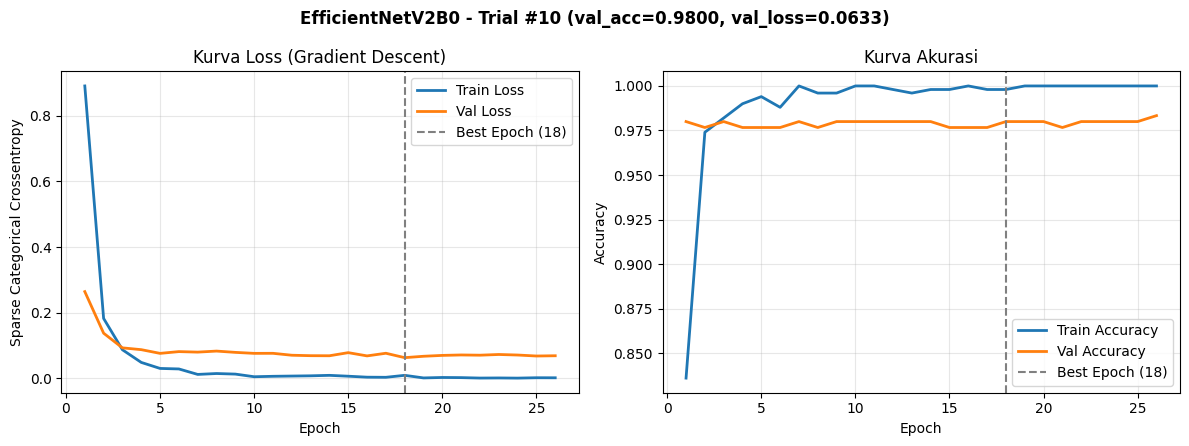

PERINGATAN: manifest belum dibuat (manifest.csv); pemeriksaan hash dilewati.
Sumber data: /kaggle/input/datasets/yonobengkel12/simplicity-224-letterbox/simplicity_224.npz (npz dataset Kaggle)

================ HASIL AKHIR TEST SET (MODEL-3: EfficientNetV2B0) ================
Trial terbaik             : #10
Akurasi Test              : 0.9800 (98.00%)
Macro F1-Score            : 0.9795
Total Parameter           : 6,249,818 (trainable: 330,506 | beku: 5,919,312)
Ukuran Berkas Model       : 26.04 MB (best_final_trial10_efficientnetv2b0.keras)
Waktu Latih Trial Terbaik : 56.25 detik
Waktu Inferensi / Gambar  : 1.829 ms/gambar (0.3658s untuk 200 gambar)

Laporan Klasifikasi per Kelas:
              precision    recall  f1-score   support

      People     0.8696    1.0000    0.9302        20
       Beach     0.9524    1.0000    0.9756        20
    Building     1.0000    0.8000    0.8889        20
         Bus     1.0000    1.0000    1.0000        20
    Dinosaur     1.0000    1.0000    1.00

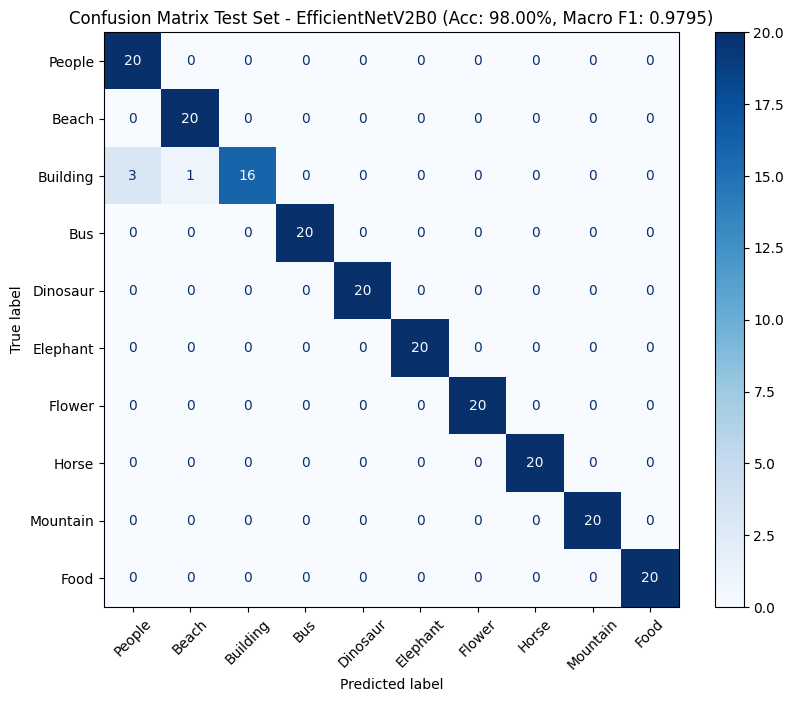

Confusion matrix disimpan ke: /kaggle/working/simplicity-cnn-comparison/model-3/confusion_matrix_efficientnetv2b0.png


In [7]:
JALANKAN_TEST = True

if JALANKAN_TEST:
    import json
    import time
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
        ConfusionMatrixDisplay,
        f1_score,
    )

    # 1. Baca konfigurasi pemenang dari trials.csv (atau CSV_AKTIF jika dijalankan langsung oleh pemenang)
    sumber_csv = (MODEL_DIR / "trials.csv")
    if not sumber_csv.is_file():
        sumber_csv = CSV_AKTIF
    daftar_hasil = baca_csv_trial(sumber_csv)
    if not daftar_hasil:
        raise RuntimeError("Belum ada data trial di CSV untuk menentukan model terbaik.")

    row_terbaik = max(daftar_hasil, key=skor_trial)
    id_terbaik = int(row_terbaik["trial"])
    print(f"Mengevaluasi Trial Terbaik #{id_terbaik} dari {sumber_csv.name}:")
    print(row_terbaik)

    # 2. Muat berkas .keras trial terbaik jika masih ada di output Kaggle;
    #    jika sesi baru (berkas .keras belum ada), latih ulang 1 konfigurasi pemenang dengan du.SEED (42).
    kandidat_keras = list(CKPT_DIR.glob(f"*trial{id_terbaik}_efficientnetv2b0.keras"))
    if kandidat_keras:
        path_model_terbaik = kandidat_keras[0]
        print(f"Memuat bobot model terbaik dari: {path_model_terbaik}")
        model_terbaik = keras.models.load_model(path_model_terbaik)
    else:
        print("Berkas .keras sesi sebelumnya tidak ditemukan; melatih ulang konfigurasi pemenang (seed=42)...")
        keras.backend.clear_session()
        bs_terbaik = int(row_terbaik["batch_size"])
        train_ds_best, val_ds_best = du.load_data(batch_size=bs_terbaik)
        model_terbaik = bangun_model(
            learning_rate=float(row_terbaik["learning_rate"]),
            unfreeze_pct=float(row_terbaik["unfreeze_pct"]),
            optimizer=row_terbaik["optimizer"],
            weight_decay=float(row_terbaik["weight_decay"]),
            dropout=float(row_terbaik["dropout"]),
            head_units=int(row_terbaik["head_units"]),
        )
        cb_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
        )
        hist_best = model_terbaik.fit(
            train_ds_best, validation_data=val_ds_best, epochs=MAX_EPOCHS, callbacks=[cb_stop], verbose=1
        )
        path_model_terbaik = CKPT_DIR / f"best_final_trial{id_terbaik}_efficientnetv2b0.keras"
        model_terbaik.save(path_model_terbaik)
        simpan_grafik_history(hist_best.history, row_terbaik, MODEL_DIR / "history_efficientnetv2b0.png")

    # 3. Evaluasi SATU KALI pada test set
    test_ds = du.load_test()
    y_true = du.ambil_label(test_ds)
    nama_kelas = du.get_class_names()

    # Warm-up 1x agar kompilasi grafik TF/XLA tidak ikut terhitung dalam waktu inferensi
    _ = model_terbaik.predict(test_ds, verbose=0)

    t0 = time.perf_counter()
    prob_pred = model_terbaik.predict(test_ds, verbose=0)
    total_infer_detik = time.perf_counter() - t0
    ms_per_gambar = (total_infer_detik / len(y_true)) * 1000.0

    y_pred = prob_pred.argmax(axis=1)
    acc_test = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")

    total_param = model_terbaik.count_params()
    trainable_param = int(sum(keras.ops.size(w) for w in model_terbaik.trainable_weights))
    non_trainable_param = total_param - trainable_param
    ukuran_mb = path_model_terbaik.stat().st_size / (1024 ** 2)

    print("\n================ HASIL AKHIR TEST SET (MODEL-3: EfficientNetV2B0) ================")
    print(f"Trial terbaik             : #{id_terbaik}")
    print(f"Akurasi Test              : {acc_test:.4f} ({acc_test * 100:.2f}%)")
    print(f"Macro F1-Score            : {macro_f1:.4f}")
    print(f"Total Parameter           : {total_param:,} (trainable: {trainable_param:,} | beku: {non_trainable_param:,})")
    print(f"Ukuran Berkas Model       : {ukuran_mb:.2f} MB ({path_model_terbaik.name})")
    print(f"Waktu Latih Trial Terbaik : {row_terbaik['train_time_sec']} detik")
    print(f"Waktu Inferensi / Gambar  : {ms_per_gambar:.3f} ms/gambar ({total_infer_detik:.4f}s untuk {len(y_true)} gambar)")
    print("==================================================================================\n")

    print("Laporan Klasifikasi per Kelas:")
    print(classification_report(y_true, y_pred, target_names=nama_kelas, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nama_kelas)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d", colorbar=True)
    ax.set_title(f"Confusion Matrix Test Set - EfficientNetV2B0 (Acc: {acc_test * 100:.2f}%, Macro F1: {macro_f1:.4f})")
    fig.tight_layout()
    path_cm = MODEL_DIR / "confusion_matrix_efficientnetv2b0.png"
    fig.savefig(path_cm, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Confusion matrix disimpan ke:", path_cm)

    # Simpan ringkasan hasil test ke hasil_test.json
    hasil_json = MODEL_DIR / "hasil_test.json"
    with open(hasil_json, "w", encoding="utf-8") as f:
        json.dump({
            "trial_terbaik": id_terbaik,
            "akurasi_test": round(float(acc_test), 6),
            "macro_f1": round(float(macro_f1), 6),
            "total_parameter": int(total_param),
            "trainable_parameter": int(trainable_param),
            "non_trainable_parameter": int(non_trainable_param),
            "ukuran_berkas_mb": round(float(ukuran_mb), 2),
            "waktu_inferensi_ms": round(float(ms_per_gambar), 3),
            "waktu_latih_detik": float(row_terbaik["train_time_sec"]),
        }, f, indent=2)
    print("Ringkasan metrik disimpan ke:", hasil_json)

    # 4. Push hasil evaluasi test ke GitHub (otomatis jika akun GitHub tersambung)
    if globals().get("PUSH_KE_GITHUB", False) and "git" in globals():
        berkas_test = [path_cm, MODEL_DIR / "history_efficientnetv2b0.png", hasil_json]
        token = globals().get("GITHUB_TOKEN")
        url_push = REPO_URL.replace("https://", f"https://x-access-token:{token}@")
        try:
            git("rebase", "--abort", cek=False)
            git("remote", "set-url", "origin", url_push)
            git("add", *[str(p.relative_to(ROOT)) for p in berkas_test if p.is_file()])
            if git("diff", "--cached", "--quiet", cek=False).returncode != 0:
                git("-c", f"user.name={GIT_NAMA}", "-c", f"user.email={GIT_EMAIL}",
                    "commit", "-m", f"model-3: hasil evaluasi test set trial #{id_terbaik} (acc={acc_test*100:.2f}%, macro_f1={macro_f1:.4f})")
                pull_res = git("-c", f"user.name={GIT_NAMA}", "-c", f"user.email={GIT_EMAIL}",
                               "pull", "--rebase", "origin", BRANCH, cek=False)
                if pull_res.returncode != 0:
                    git("rebase", "--abort", cek=False)
                    pesan_pull = (pull_res.stderr or pull_res.stdout).replace(token, "***")
                    print(f"Peringatan pull saat test push:\n{pesan_pull.strip()}")
                hasil = git("push", "origin", f"HEAD:{BRANCH}", cek=False)
                if hasil.returncode != 0:
                    pesan_push = (hasil.stderr or hasil.stdout).replace(token, "***")
                    print(f"Peringatan push saat test push:\n{pesan_push.strip()}")
                else:
                    print(f"Berhasil push hasil evaluasi test ke {REPO_URL} (branch {BRANCH}).")
            else:
                print("Tidak ada perubahan baru pada berkas evaluasi test untuk di-commit.")
        finally:
            git("remote", "set-url", "origin", REPO_URL, cek=False)
    else:
        print("\nHasil evaluasi test belum di-push ke GitHub (PUSH_KE_GITHUB belum aktif / GitHub belum tersambung).")
else:
    print("Evaluasi test belum dijalankan (JALANKAN_TEST = False).")